# **Métodos Cuantitativos**
**Doctorado en T.I**

Presentado por: Edgar Rodrigo Enríquez Rosero

Al docente: PhD. Gerardo Avendaño

2026



## Introducción

El presente notebook se basa en datos relacionados con la seguridad digital, para ellos se tomaron muestras en diferentes países del mundo y se aprecia que fueron muestras aleatorias con respecto a la edad y a la educación de los ecuestados.
Mediante el análisis realizado se aplican diferentes modelos estadísticos que permitan analizar y comprobar las hipótesis planteadas, así como el conocer aquellos sesgos que se podrían generar a raíz de respuestas equivocadas o mal planteadas o mal interpretadas por parte de los encuestados.

El proceso que se lleva a cabo se divide en 5 secciones:

*   Cargue, verificación de integridad y limpieza del dataset (Datos erróneos, duplicidad e inconsisencias): En esta etapa se evalúa la estructura del conjunto de datos mediante la comprobación de dimensiones, la detección de valores faltantes (identificando patrones de no respuesta) y la revisión de registros duplicados o inconsistencias tipográficas.
*   Tratamiento de datos: Se identifican y gestionan variables con tipos de datos mixtos u objetos con entradas atípicas, de tal manera que se asegure una correcta interpretación numérica y discriminación por categoría.
*   Estadísticas: Medidas de tendencia central y formas de distribución: Esto permite caracterizar el comportamiento de la población de estudio de acuerdo con la información existente en el dataset.
*   Detección de valores atípicos: El empleo de métodos gráficos como los diagramas de caja y gráficos de violín y de métodos analíticos como puntuación Z y la regla del IQR permiten identificar anomalías en las distribuciones.
*   Comparación de grupos mediante pruebas y modelamiento de relaciones: Este proceso permite una visualización científica en la cual se implementan histogramas, funciones de densidad de probabilidad, matrices de correlación y gráficos bivariados para ilustrar las relaciones y tendencias predominantes entre las variables de interés.

El proceso realizado permite comprender mejor el perfil sociodemográfico de los participantes y establece un punto de partida confiable para futuras investigaciones o modelos predictivos dede el punto de vista de la seguridad digital y por último, se presentan las conclusiones del trabajo realizado.

El acelerado avance de la transformación digital ha expuesto a usuarios globales a diversos riesgos de ciberseguridad. Este estudio analiza una muestra internacional estructurada con el fin de determinar cómo los factores sociodemográficos y educativos condicionan tanto la percepción de vulnerabilidad como la adopción de comportamientos protectores en el entorno digital.
       



# Hipótesis de Investigación Planteadas

**Nivel de Educación vs. Percepción de Ciberseguridad**

Analizando el dataset se observa que más del 87% de las personas tienen educación media o alta, por lo tanto se desea demostrar si la gente con más estudio siente que sabe más de ciberseguridad que los que tienen menos estudios.

*   Hipótesis Nula ($H_0$): El nivel educativo de las personas no afecta su conocimiento en ciberseguridad.
*   Hipótesis ($H_1$): La gente con educación superior (categorías 3 y 4) tiene mayor puntaje de percepción de competencia que los de educación básica o media (categorías 1 y 2).  A mayor nivel alcanzado de educación formal (Education), se incrementa lineal y monotonamente la percepción del riesgo digital y la implementación de mecanismos de autenticación avanzada.

* Hipótesis $H_2$ (Brecha de Género y Exposición a Incidentes): Existe una diferencia estadísticamente significativa en el nivel de adopción de prácticas de seguridad digital según la autoidentificación de género de los encuestados.

* Hipótesis $H_3$ (Determinantes Multivariados del Comportamiento Seguro):El nivel educativo y la edad influyen de manera conjunta y positiva en el índice global de preparación en seguridad digital, manteniendo constante la procedencia geográfica (Country).

In [ ]:
# Importar librerías para el dataset
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Importar el archivo con el dataset
from google.colab import drive
drive.mount ('/content/drive')
file_path ="/content/drive/My Drive/SurveyResponses_DigitalSecurityAroundTheWorld.csv"

# Cargar el dataset
df = pd.read_csv(file_path, low_memory=False) # El parámetro low_memory=False : Lee todas las filas de cada columna antes de decidir el tipo de dato para evitar advertencias o errores por tipos de datos mixtos, asegura la interpretación correcta de los datos
# Visualizar las primeras filas del dataset
df.head()



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,ID,Country,Gender,Gender_SelfDescription,Age,Education,Ethnicity,q1r1,q1r2,q1r3,...,q22r1,q22r2,q22r3,q22r4,q22r5,q22r6,q22r7,q22r8,q25,q26
0,0,5,2.0,NaN,4.0,3.0,NaN,1,0,1,...,1,1,1,1,1,1,1,1.0,2.0,2.0
1,1,5,2.0,NaN,2.0,3.0,NaN,1,0,1,...,1,2,2,2,4,3,5,5.0,1.0,2.0
2,2,5,2.0,NaN,3.0,2.0,NaN,1,1,0,...,1,2,2,1,3,4,5,5.0,1.0,2.0
3,3,5,1.0,NaN,3.0,3.0,NaN,1,1,1,...,3,2,3,3,3,2,3,3.0,1.0,1.0
4,4,5,1.0,NaN,2.0,3.0,NaN,1,1,1,...,1,1,1,4,4,4,4,4.0,2.0,2.0


#Verificación de integridad
Para verificar la integridad del dataset se hizo el análisis a través del código que se presenta a continuación:

In [ ]:
#Corrección del dataset que según el diccionario de variables: `q4r8` contiene **una** celda de texto ("getting my information") entre los códigos 1–8.
df["q4r8"] = pd.to_numeric(df["q4r8"], errors="coerce") # verifica en el dataframe si existe un valor inválido por lo tanto, lo convierte en un valor nulo
filas, columnas = df.shape
print(f"Dimensiones del dataset: {filas} filas x {columnas} columnas")
assert filas == 12351, f"Se esperaban 12.351 registros, pero se encontraron {filas}" # Comprobación de datos: Se compara las filas encontradas con la cantidad de registros existentes en el dataset antes de subirlo al drive
assert columnas == 248, f"Se esperaban 248 variables, pero se encontraron {columnas}" # Comprobación de datos: Se compara las columnas encontradas con la cantidad de variables existentes en el dataset antes de subirlo al drive

print("Verificación correcta: El dataset consta de 12.351 registros y 248 variables.")

Dimensiones del dataset: 12351 filas x 248 columnas
Verificación correcta: El dataset consta de 12.351 registros y 248 variables.


# Diagnóstico de calidad:

**Validación de la variable q4r8:** Esta variable presentó entradas alfanuméricas heterogéneas derivadas de errores de codificación en el formulario original. Se estandariza mediante coerción numérica (pd.to_numeric), imputando valores no numéricos como *NaN* para preservar el cálculo escalar sin distorsionar el resto de ítems.

**Patrón de Faltantes e Inconsistencias Específicas:** Determinadas variables presentan un porcentaje de ausencia superior al 90% (por ejemplo Ethnicity). Esto no responde a un sesgo aleatorio de no respuesta (*Missing Not at Random* - MNAR), sino a un diseño muestral condicionado donde el módulo étnico fue aplicado exclusivamente en la submuestra de Estados Unidos. Mantener la columna es vital para subsubsistemas de análisis local, pero debe omitirse en regresiones globales para evitar la pérdida masiva de grados de libertad.

El resultado se presenta a continuación:

In [ ]:
# Calculo de cantidad y porcentaje de valores faltantes por variable
vrfaltantes_df = pd.DataFrame({  # Se crea un nuevo dataframe con las columnas de Valores_Faltantes y el Porcentaje clasificadas por categoría
    'Valores_Faltantes': df.isnull().sum(), # Cuenta la cantidad total de celdas vacías o etiquetadas en el dataframe como NaN Not a Number
    'Porcentaje(%)': (df.isnull().sum() / len(df)) * 100 # Cacula el porcentaje de celdas vacías
})
# Filtrar las variables que contienen al menos un valor faltante en orden de % mayor a menor
tabla_faltantes = vrfaltantes_df[vrfaltantes_df['Valores_Faltantes'] > 0].sort_values(
    by='Porcentaje(%)', ascending=False
)
print(f"Total de variables con valores faltantes: {len(tabla_faltantes)} de {df.shape[1]}")
display(tabla_faltantes)

Total de variables con valores faltantes: 161 de 248


,Valores_Faltantes,Porcentaje(%)
Gender_SelfDescription,12068,97.708688
q8r10oer1,11776,95.344507
Ethnicity,11300,91.490568
Age,3074,24.888673
q12r8,2742,22.200632
...,...,...
q21r3,32,0.259088
q21r5,28,0.226702
q21r15,20,0.161930
q4r8,1,0.008097


**Duplicados e  inconsistencias.**
Para hallar estos 2 ítems, se realiza mediante el siguiente script:


In [ ]:
duplicate_rows = df.duplicated().sum()
print(f"Filas duplicadas: {duplicate_rows}")

# Detección de duplicados por identificador único (ID)
if 'ID' in df.columns:
    duplicate_ids = df['ID'].duplicated().sum()
    print(f"Registros con 'ID' duplicado: {duplicate_ids}")
    if duplicate_ids > 0:
        print("IDs duplicados:", df[df['ID'].duplicated(keep=False)]['ID'].head().tolist())
    else:
        print("NO existen IDs duplicados")

Filas duplicadas: 0
Registros con 'ID' duplicado: 0
NO existen IDs duplicados


**Tipos de Datos incorrectos y mixtos**

El script que se presenta a continuación permite identificar si existen múltiples tipos de datos.
Documentar las decisiones sobre el tratamiento de cada problema encontrado.

La variable Ethnicity solo aplica para la submuestra de Estados Unidos. (Country == 12, ~91.5% NaN global). No se debe descartar esa columna ni borrar filas globales por este patrón estructurado.

In [ ]:
print("Tipos de datos asignados:")
print(df.dtypes.value_counts())
# Identificación de columnas que contienen múltiples tipos de datos
mixed_type_columns = []
for col in df.columns:
    types_in_col = df[col].dropna().apply(type).unique()
    if len(types_in_col) > 1:
        type_names = [t.__name__ for t in types_in_col]
        mixed_type_columns.append((col, type_names))

print(f"\nColumnas con tipos de datos mixtos dentro de la misma columna ({len(mixed_type_columns)} encontradas):")
for col, types in mixed_type_columns:
    print(f" - Columna '{col}': contiene tipos {types}") # Detección de columnas guardadas como objetos que contienen valores numéricos con textos atípicos
print("\nEvaluación de valores no numéricos en columnas de tipo 'object':")
object_cols = df.select_dtypes(include=['object']).columns

for col in object_cols:
    converted = pd.to_numeric(df[col], errors='coerce')
    non_numeric_mask = converted.isna() & df[col].notna()
    non_numeric_count = non_numeric_mask.sum()

    if non_numeric_count > 0:
        sample_non_numeric = df.loc[non_numeric_mask, col].unique()[:5]
        print(f" - Columna '{col}': {non_numeric_count} registros no se pudieron convertir a número. Muestra: {sample_non_numeric}")

Tipos de datos asignados:
float64    163
int64       83
object       2
Name: count, dtype: int64

Columnas con tipos de datos mixtos dentro de la misma columna (0 encontradas):

Evaluación de valores no numéricos en columnas de tipo 'object':
 - Columna 'Gender_SelfDescription': 249 registros no se pudieron convertir a número. Muestra: ['Sono una persona semplice' 'sono entusiasta della vita' 'Alto e robusto'
 'xx' 'Donna']
 - Columna 'q8r10oer1': 574 registros no se pudieron convertir a número. Muestra: ['google' 'documentazione tecnica online' 'Giornali online'
 'le informazioni che le banche con cui lavoro mi comunicano' 'Google']


Al ejecutar el script se encontró que la columna de descripción de género (Gender_SelfDecription) contiene cualidades en 249 registros que no se pueden convertir a números.

De igual manera ocurre con 574 registros de la pregunta q8r10oer1.
De estos datos que se evaluaron, no es posible generalizar o tomar algún patrón en particular, por lo tanto no podrían cuantificarse para realizar una caracterización y serían excluyentes para analizar.

**Inconsistencias y tipos de datos incorrectos**

El siguiente script permite encontrar las inconsistencias y los tipos de datos incorrectos:

In [ ]:
# Validación de rangos en variables sociodemográficas para estudio
demo_cols = ['Age', 'Gender', 'Education', 'Country']
existing_demo = [c for c in demo_cols if c in df.columns]

if existing_demo:
    print("\nResumen estadístico de variables sociodemográficas (para verificar valores fuera de rango):")
    print(df[existing_demo].describe().T[['min', 'mean', 'max', 'count']])


Resumen estadístico de variables sociodemográficas (para verificar valores fuera de rango):
           min      mean   max    count
Age        1.0  2.818152   4.0   9277.0
Gender     1.0  1.566895   4.0  12258.0
Education  1.0  2.348636   4.0  12351.0
Country    1.0  6.537284  12.0  12351.0


# Estadisticas robustas
Calcular medidas de tendencia central: Media, Mediana y Moda
Medidas de dispersión: Desviación estándar, Rango intercuartílico — IQR, MAD, Forma de las distribuciones: Asimetría, curtosis.
Usar pandas y scipy.stats.

In [ ]:
def calcular_estadisticas_descriptivas(data, columnas=None):
    #    Calcular medidas de tendencia central, dispersión y forma para variables numéricas.
    if columnas is None:
        columnas = data.select_dtypes(include=[np.number]).columns  # Selecciona todas las columnas numéricas por defecto
    resultados = []
    for col in columnas:
        s = data[col].dropna()  # Elimina valores nulos (NaN) para realizar los cálculos correctamente
        if len(s) == 0:
            continue

        # Medidas de tendencia central: Media y Mediana obtenidos con pandas y moda con scipy
        media = s.mean()
        mediana = s.median()
        moda = stats.mode(s, keepdims=True).mode[0]

        # Medidas de dispersión DEsivación estándar con pandas, iqr y Mad calculada con Scipy
        std = s.std()
        iqr = stats.iqr(s)
        mad = stats.median_abs_deviation(s)

        # Medidas de Forma
        asimetria = stats.skew(s)
        curtosis = stats.kurtosis(s)

        resultados.append({
            'Variable': col,
            'Media': media,
            'Mediana': mediana,
            'Moda': moda,
            'Desv_Estandar': std,
            'IQR': iqr,
            'MAD': mad,
            'Asimetria': asimetria,
            'Curtosis': curtosis
        })

    return pd.DataFrame(resultados)


# Medidas de las variables sociodemográficas
cols_interes = ['Age', 'Gender', 'Education', 'Country']
df_resumen = calcular_estadisticas_descriptivas(df, columnas=cols_interes)

print(df_resumen.round(4).to_string(index=False))

 Variable  Media  Mediana  Moda  Desv_Estandar  IQR  MAD  Asimetria  Curtosis
      Age 2.8182      3.0   4.0         1.0309  2.0  1.0    -0.2896   -1.1445
   Gender 1.5669      2.0   2.0         0.6232  1.0  1.0     1.2034    2.8709
Education 2.3486      2.0   3.0         0.7042  1.0  1.0    -0.4329   -0.6647
  Country 6.5373      7.0   7.0         3.4469  6.0  3.0    -0.0141   -1.2105


# Gráficas detección de outliers

Se implementan dos métodos, el gráfico mediante los gráficos de Boxplot y Violin Plot; y el método analítico a través de Z-score y la regla IQR


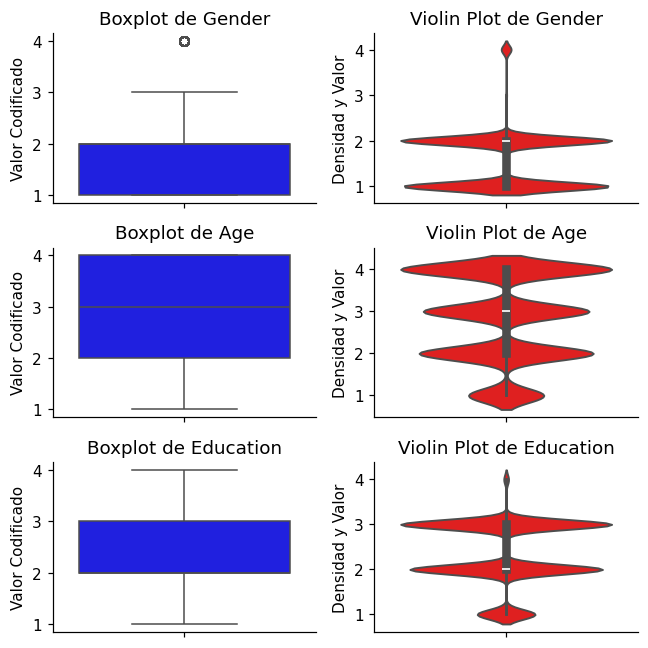

ANÁLISIS DE OUTLIERS EN: 'Gender'
Registros válidos: 12257
Z-Score (|Z| > 3): 283 outliers (2.31%)
Regla IQR (Q1-1.5*IQR, Q3+1.5*IQR): 283 outliers (2.31%)
Límites IQR: [-0.5, 3.5]

ANÁLISIS DE OUTLIERS EN: 'Age'
Registros válidos: 9276
Z-Score (|Z| > 3): 0 outliers (0.00%)
Regla IQR (Q1-1.5*IQR, Q3+1.5*IQR): 0 outliers (0.00%)
Límites IQR: [-1.0, 7.0]

ANÁLISIS DE OUTLIERS EN: 'Education'
Registros válidos: 12350
Z-Score (|Z| > 3): 0 outliers (0.00%)
Regla IQR (Q1-1.5*IQR, Q3+1.5*IQR): 0 outliers (0.00%)
Límites IQR: [0.5, 4.5]



In [ ]:
# Métodos gráficos
def graficar_outliers(df, columnas):
    fig, axes = plt.subplots(len(columnas), 2, figsize=(6,2 * len(columnas)))
    for i, col in enumerate(columnas):
        data_clean = df[col].dropna()

        # Boxplot
        sns.boxplot(y=data_clean, ax=axes[i, 0], color='blue')
        axes[i, 0].set_title(f'Boxplot de {col}')
        axes[i, 0].set_ylabel('Valor Codificado')

        # Violin Plot
        sns.violinplot(y=data_clean, ax=axes[i, 1], color='red')
        axes[i, 1].set_title(f'Violin Plot de {col}')
        axes[i, 1].set_ylabel('Densidad y Valor')

    plt.tight_layout()
    plt.savefig('analisis_outliers.png')
    plt.show()

# Grafico de variables de género, edad y educación
graficar_outliers(df, ['Gender', 'Age', 'Education'])

# Métodos analíticos

def detectar_outliers_analiticos(df, columna):
    s = df[columna].dropna()  # Elimina o ignora los espacios en blanco

    # Cálculo de Z-Score Estandarizado
    z_scores = np.abs(stats.zscore(s)) # Calcula la magnitud de la desviación estándar
    outliers_z = s[z_scores > 3]  # Si el valor es superior a 3 veces la desv estandar con respecto a la media, se considera un outlier
                                  # y almacena en el vector aquellos datos de s que cumplan la regla (V/r Verdadero)

    # Regla del Rango Intercuartílico (IQR)
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers_iqr = s[(s < limite_inferior) | (s > limite_superior)]

    print(f"ANÁLISIS DE OUTLIERS EN: '{columna}'")
    print(f"Registros válidos: {len(s)}")
    print(f"Z-Score (|Z| > 3): {len(outliers_z)} outliers ({len(outliers_z)/len(s)*100:.2f}%)")
    print(f"Regla IQR (Q1-1.5*IQR, Q3+1.5*IQR): {len(outliers_iqr)} outliers ({len(outliers_iqr)/len(s)*100:.2f}%)")
    print(f"Límites IQR: [{limite_inferior}, {limite_superior}]\n")

# Ejecutar análisis en variables clave
for col in ['Gender', 'Age', 'Education']:
    detectar_outliers_analiticos(df, col)



# Resultado del análisis

Para el criterio de "Género" - "Gender", se encuentra que se tienen 283 outliers, equivalentes a 2.31% , este resultado se dió aplicando Z-score y Regla IQR, por lo tanto se deduce que cualquiera de los 2 métodos son confiables y válidos.

El valor encontrado supera al valor ideal de 0.27%, por lo tanto se consideran valores atípicos y podrian:
1. Verificar si los valores ingresados corresponden a un error de digitación
2. Pueden considerarse como anomalías que podrían centrar la atención en el estudio.
3. Eliminarse si se consideran errores.
4. Conservarse

Al analizar el dataset, el resultado coincide con aquellos datos que tienen un valor de 4, Revisando la pregunta el género se podría marcar como 1. Masculino, 2. Femenino, 3. Prefiero no decir, 4. Indeterminado y esta ultima respuesta es la que genera el outlier alto y que podría considerarse como una minoría de género, de acuerdo con lo anterior, podrían omitirse estos datos ya que no se considerarían significativos o relevantes, aunque traería como consecuencia un sesgo de selección minoritaria, por lo tanto deberían conservarse.

Con relación a los resultados obtenidos por "Edad" - "Age" y "Educación" - "Education", se observa un resultado de 0 y 0%, esto indica que el dataset es compacto, simétrico, no tiene extremos y no supera 3 veces la desviación estándar, por lo tanto para analizar estas características, no es necesario realizar una limpieza o depuración del dataset.  

# Visualización científica

Graficación mediante histogramas y densidades, scatter plots bivariados, heatmap de correlaciones, pairplot de las variables de interés.

Se evalúan las distribuciones empíricas mediante funciones de densidad kernel ($KDE$) y se estiman tanto la **Correlación de Pearson** (relación lineal) como la **Correlación de Spearman** (relación monótona ordinal).

Vinculación con las Hipótesis ($H_1$ y $H_2$):
* La evaluación del coeficiente de Spearman entre *Education* y las variables de percepción/adopción permite comprobar $H_2$. Si $\\rho_{spearman} > 0$ con $p < 0.05$, se valida empíricamente que la madurez educativa impulsa conductas de protección digital.

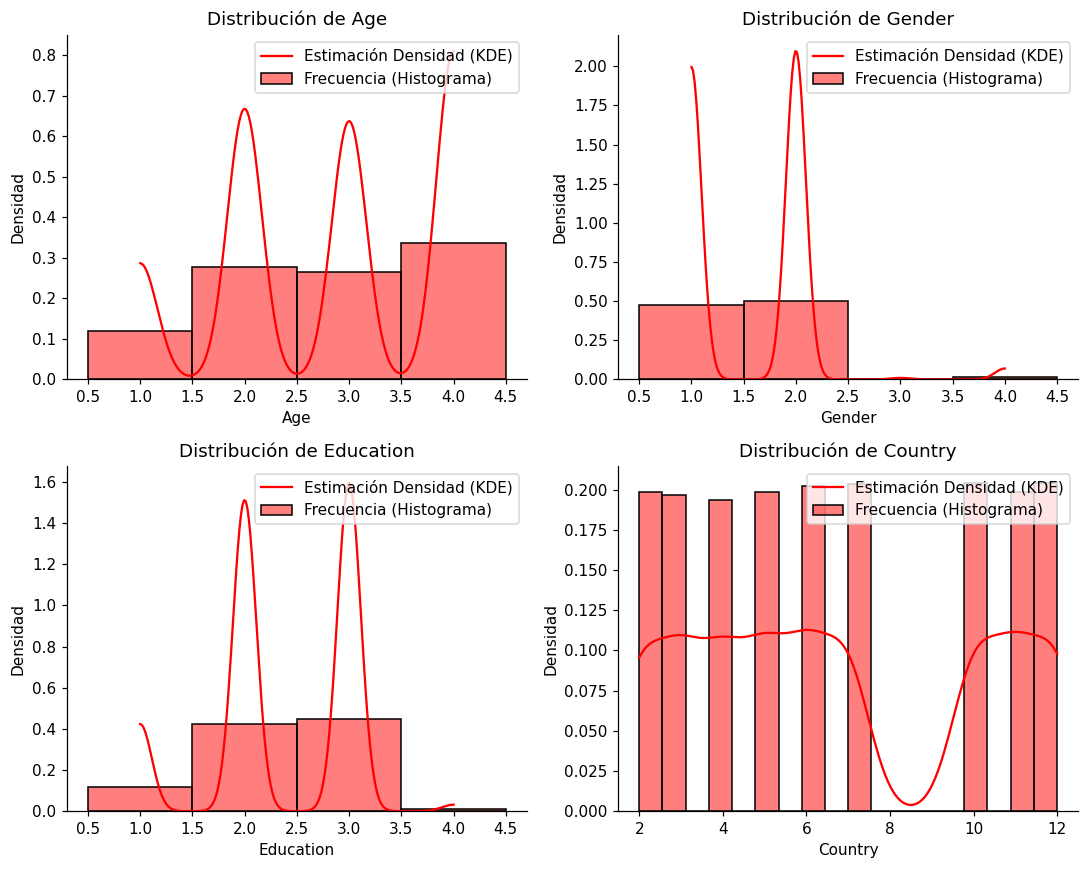

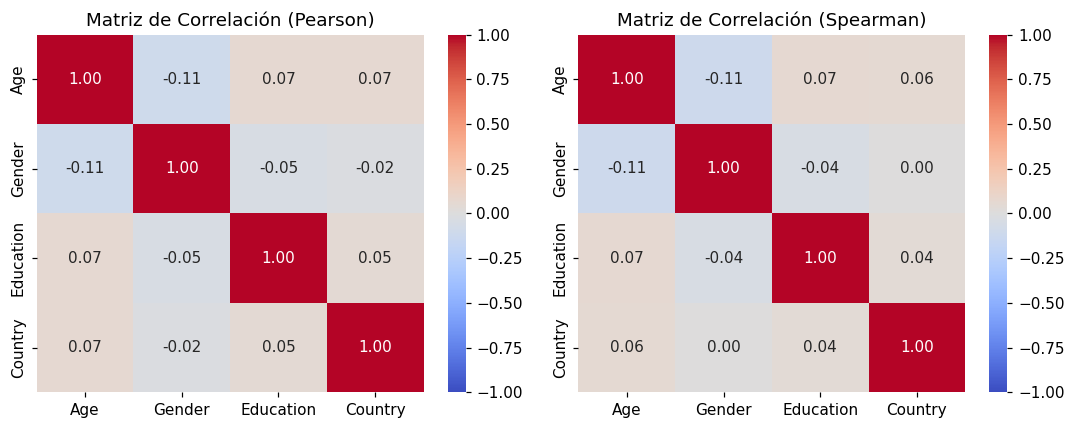

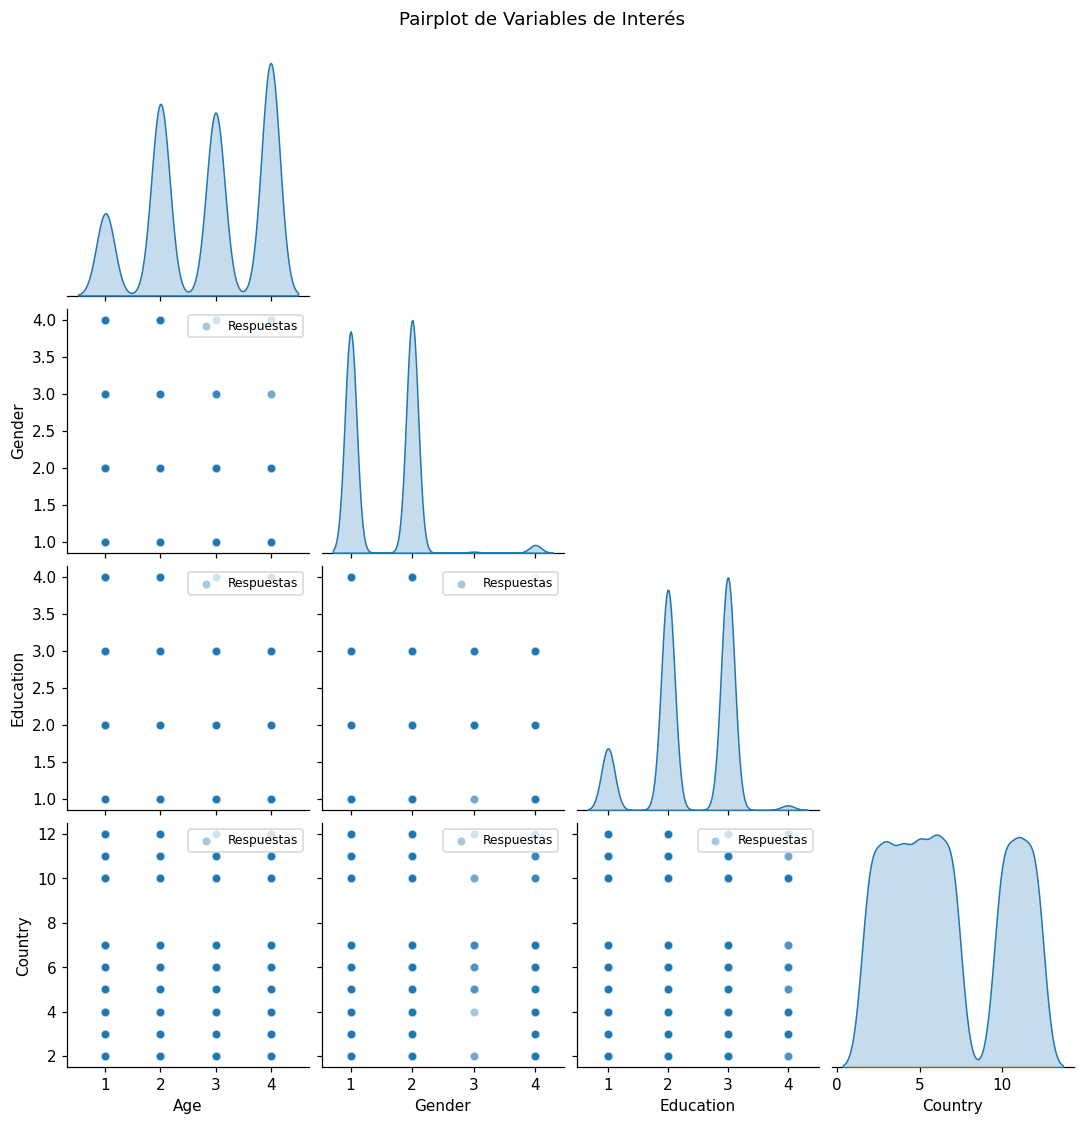

In [ ]:
key_vars = ['Age', 'Gender', 'Education', 'Country']
df_sub = df[key_vars].dropna()

# HISTOGRAMAS Y DENSIDADES
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, col in enumerate(key_vars):
    sns.histplot(
        df_sub[col],
        kde=True,
        ax=axes[i],
        color='red',
        stat="density",
        discrete=True if col in ['Age', 'Gender', 'Education'] else False,
        label='Frecuencia (Histograma)'
    )
    if axes[i].lines:
        axes[i].lines[0].set_label('Estimación Densidad (KDE)')

    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Densidad')
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

# 2. HEATMAP DE PEARSON Y SPEARMAN

corr_pearson = df_sub.corr(method='pearson')
corr_spearman = df_sub.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Heatmap Pearson
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], fmt='.2f')
axes[0].set_title('Matriz de Correlación (Pearson)')

# Heatmap Spearman
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], fmt='.2f')
axes[1].set_title('Matriz de Correlación (Spearman)')

plt.tight_layout()
plt.show()

# 3. PAIRPLOT (SCATTER PLOTS BIVARIADOS Y DENSIDADES CRUZADAS)
pairplot_fig = sns.pairplot(
    df_sub,
    corner=True,
    diag_kind='kde',
    plot_kws={'alpha': 0.4, 's': 30, 'label': 'Respuestas'}
)

for ax in pairplot_fig.axes.flatten():
    if ax is not None:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(handles=handles, labels=labels, loc='upper right', fontsize=8)

pairplot_fig.fig.suptitle('Pairplot de Variables de Interés', y=1.02)
plt.show()

# Análisis de las gráficas

**Historias y densidades**

Describe la forma y concentración de la muestra N = 9211 discriminada por cada variable analizada:

*  *Age* (Edad): Muestra una distribución sesgada hacia los grupos de mayor edad. La categoría 4 es la más frecuente con un 33.7%, el segundo lugar lo ocupa el grupo 2 con un 27.8% y el grupo 3 con un porcentaje del 26.5%. La menor representación la tiene el grupo 1 con un 11.9%, que posiblemetne sea el grupo más joven en el dataset.
*   *Gender* (Género): Presenta una distribución prácticamente bimodal y equitativa entre los dos géneros principales codificados como 1 que representa el 47.8% y el 2 con un valor porcentual del 50.3%. Las categorías 3 y 4 representan opciones minoritarias que suman menos del 2% de la muestra total.
*   *Education* (Nivel Educativo): Se puede observar que la mayor concentración la tienen las categorías intermedias 2 y 3 equivalentes al 87% de los encuestados, la primera con un 42.4% y la segunda con un 44.8%. La educación básica o no especificada, categorizada como 1, tiene un valor de 11.9% y los postgrados u otros categorizados como 4, se consideran la minoría con un 0.9%.
*  *Country* (País): La distribución podría considerarse uniforme basado en los códigos numéricos de países, indicando un muestreo balanceado geográficamente en la aplicación de la encuesta.

**Matriz de Correlación**

Tomando las gráficas Heatmap de Pearson y Spearman, las matrices miden el grado de asociación lineal (Pearson) y monótona (Spearman) entre las variables, clasificadas de la siguiente manera:

*   Relación Nula/Débil: Todos los coeficientes de correlación se sitúan muy
cercanos a cero, con un rango entre -0.11 hasta 0.07. La correlación lineal más "fuerte" encontrada en el conjunto es la de Age vs Gender con $r \approx$ -0.11,aunque estadísticamente se considera débil, representa una ligera tendencia a encontrar una proporción menor de un género en los grupos de edad más avanzada dentro del muestreo.
*   Relación positiva mínima: Representada en la correlación Age vs Education $r \approx$ 0.07, de ella podría concluirse que a mayor edad hay una tendencia a tener un mayor nivel educativo.
* Inexistencia de correlación: La variable demográfica Country, tiene valores de correlación muy bajos, de los cuales sólo Country vs Age se asemejan a una relación postiva mínima como en el caso anterior, esto confirma que el mapeo de los países es independiente del género o nivel educativo posiblemente hasta la edad de los encuestados.

**Pairplot - Dispersión Bivariada**

El gráfico de dispersión cruzado complementa los hallazgos de la matriz de correlación, donde la mayoría de las variables tienen una categoría con la cual se codificó numéricamente, en la gráfica se aprecia que los datos se alinean en una cuadrícula, donde se tiene en cuenta la densidad de puntos y donde la superposición de puntos genera tonos más oscuros, que puede compararse con la modas de los histogramas entre Age y Education. Tambien se puede observar una concentración densa en la combinación de Gender con todas las edades.

En la gráfica no se observan grupos ni tendencias por lo tanto se podría inferir que no existen dependencias directas fuertes entre los datos sociodemográficos analizados








# Semanas 6 y 7
**Comparación de grupos (pruebas de hipótesis / ANOVA) y modelamiento de relaciones (regresión lineal múltiple)**

## Definiciones y Codificaciones

| Variable | Definición | Justificación |
|---|---|---|
| conocimiento_score | **Media** de **q6r1 – q6r22**` (familiaridad con términos de seguridad: 1 = nunca oído … 5 = sé muy bien cómo funciona) | Bloque de conocimiento del diccionario. No requiere invertir ítems: la inversión aplica a las baterías de acuerdo (**q9 – q16**), que no se usan aquí |
|proteccion_score| **Suma** de **q20r2 – q20r14** (Medidas de protección usadas; rango 0–13) | Bloque de comportamiento protector. Se excluye **q20r1** ("ninguna medida"): Clasificada como excluyente si se suma contaría "no hacer nada" como una medida |
|grupo_weird| **WEIRD:** Alemania, Israel, Italia, Polonia, Suecia, Reino Unido, EE. UU. · **No-WEIRD:** China, India, México, Arabia Saudita, Sudáfrica | **Country** es la base del corte. Israel y Polonia son los casos más discutibles → análisis de sensibilidad |
|Education| 1 = Bajo, 2 = Medio, 3 = Alto. 4(Otro) se excluye de las comparaciones y del modelo | No guarda relación con los niveles definidos |
|Age| 1 = 18–24, 2 = 25–39, 3 = 40–54, 4 = 55+ (ordinal; sin dato en China, Arabia Saudita y Sudáfrica) | Se usa como numérica según requisito |
|q25| 1 = Sí, 2 = No tiene experiencia práctica en TI. El valor atípico 12 pasa a NaN | |
| Faltantes | Celdas vacías (NaN). No se recodifica 9999: no aparece en los datos exportados | |

In [ ]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
APLICAR_CONTROL = True      # excluir quienes fallan la pregunta de control q13r11
rng = np.random.default_rng(42)

PAISES = {1: "China", 2: "Alemania", 3: "India", 4: "Israel", 5: "Italia", 6: "México", 7: "Polonia",
          8: "Arabia Saudita", 9: "Sudáfrica", 10: "Suecia", 11: "Reino Unido", 12: "EE. UU."}
WEIRD = {2, 4, 5, 7, 10, 11, 12}
print(pd.crosstab(df["Country"].map(PAISES), df["q13r11"]))

esperado = df.groupby("Country")["q13r11"].transform(lambda s: s.mode().iloc[0])
df["control_ok"] = df["q13r11"] == esperado
print("Fallan el control:", (~df["control_ok"]).sum(), "de", len(df))
if APLICAR_CONTROL:
    df = df[df["control_ok"]].copy()
print("N analítico:", len(df))

q13r11           4.0   5.0
Country                   
Alemania        1019     0
Arabia Saudita  1018     0
China           1008     0
EE. UU.         1050     0
India           1011     0
Israel          1011     0
Italia          1019     0
México          1045     0
Polonia            0  1054
Reino Unido     1018     0
Sudáfrica       1048     0
Suecia          1049     0
Fallan el control: 0 de 12350
N analítico: 12350


**Criterio de exclusión.** Se observa un valor esperado de 4 en todos los países, excepto en Polonia, donde todos los participantes (1.054) marcaron 5 como respuesta. La respuesta unánime en un país se podría interpretar como una diferencia o errores de interpretación o traducción del cuestionario que a una respuesta de baja calidad. El DataMap la define: "[Q13r11] This is a control question. Please click on the second selection option from the right / from the bottom.". En resumen es una pregunta de control posiblemente irrelevante para el estudio, pero si se exige que el valor sea 4, implica que los datos de Polonia serían eliminados, por lo tanto se asume como correcta la respuesta modal de cada país, el valor que se excluye sería la desviación que ocurre donde existe un único caso, con el valor de 2. Si se cambia la variable **APLICAR_CONTROL = False** los resultados podrían consdierarse prácticamente idénticos.

## Recodificaciones e índices
Como se mencionó en la sección anterior, es necesario filtrar o excluir algunos datos que no cotribuyen al análisis, el ejemplo que se indicó en dicha sección es el caso de la educación clasificada como alto, medio o bajo, donde otro con un valor de 4 no es relevante o no tiene significado dentro de estudio

In [ ]:
df["pais"]        = df["Country"].map(PAISES)
df["grupo_weird"] = np.where(df["Country"].isin(WEIRD), "WEIRD", "No-WEIRD")
df["edu_cat"]     = df["Education"].map({1: "Bajo", 2: "Medio", 3: "Alto"})      # 4 = Otro Se omite: NaN
df["q25"]         = df["q25"].where(df["q25"].isin([1, 2]))                        # 12, Se omite: NaN

q6  = [f"q6r{i}"  for i in range(1, 23)]     # familiaridad con términos de seguridad
q20 = [f"q20r{i}" for i in range(2, 15)]     # medidas de protección (q20r1 = "ninguna medida", se excluye)

df["conocimiento_score"] = df[q6].apply(pd.to_numeric, errors="coerce").mean(axis=1)  # Recorre todas las celdas de la columnas y forza su conversión a números.
                                                                                      # Si hay texto que no se pueda convertir, lo transforma en NaN
                                                                                      # mean(axis=1) Calcula el promedio aritmético para cada persona de sus respuestas
df["proteccion_score"]   = df[q20].apply(pd.to_numeric, errors="coerce").sum(axis=1, min_count=13)
                                                                                      # min_count: Parámetro de control de calidad útil en encuestas
                                                                                      # Indica a Pandas que solo calcule la suma si la persona respondió al menos 13 preguntas.
                                                                                      # en caso contrario no genera un promedio para esa persona
print("q20r1 marcada junto con otra medida:", ((df["q20r1"] == 1) & (df[q20].sum(axis=1) > 0)).sum())   # 0

def cronbach(X):              # Alfa de Cronbach: Indicador estadístico que mide la consistencia interna o fiabilidad de ítems o preguntas de una encuesta
    X = X.dropna();           # Elimina las filas que contienen valores nulos (NaN) para evitar errores en los cálculos de varianza
    k = X.shape[1]            # Obtiene el número total de columnas (ítems o preguntas) analizadas
    return k / (k - 1) * (1 - X.var().sum() / X.sum(axis=1).var())

print("alpha conocimiento (q6) :", round(cronbach(df[q6].apply(pd.to_numeric, errors="coerce")), 3))
print("alpha protección (q20)  :", round(cronbach(df[q20]), 3))
print("Coeficiente de correlación de Pearson - r(conocimiento, protección):", round(df[["conocimiento_score", "proteccion_score"]].corr().iloc[0, 1], 3))  # coeficiente de correlación de Pearson (r)
df[["conocimiento_score", "proteccion_score"]].describe().round(3)

por_pais = (df.groupby(["Country", "pais", "grupo_weird"])
              .agg(n=("ID", "size"), conocimiento=("conocimiento_score", "mean"), proteccion=("proteccion_score", "mean"))
              .round(2).reset_index().drop(columns="Country"))
display(por_pais)
print(df["edu_cat"].value_counts(dropna=False))

q20r1 marcada junto con otra medida: 0
alpha conocimiento (q6) : 0.944
alpha protección (q20)  : 0.725
Coeficiente de correlación de Pearson - r(conocimiento, protección): 0.497


,pais,grupo_weird,n,conocimiento,proteccion
0,China,No-WEIRD,1008,3.38,4.70
1,Alemania,WEIRD,1019,3.09,5.39
2,India,No-WEIRD,1011,3.59,6.17
3,Israel,WEIRD,1011,3.12,4.95
4,Italia,WEIRD,1019,3.17,4.77
5,México,No-WEIRD,1045,3.06,4.99
6,Polonia,WEIRD,1054,3.26,4.53
7,Arabia Saudita,No-WEIRD,1018,3.18,5.41
8,Sudáfrica,No-WEIRD,1048,3.39,6.38
9,Suecia,WEIRD,1049,2.99,4.73


edu_cat
Alto     5588
Medio    5102
Bajo     1534
NaN       126
Name: count, dtype: int64



# Escala general de interpretación Alfa de Cronbach

*   0,90 o más: Excelente (confiabilidad excepcional; precaución si supera 0,95, ya que puede indicar redundancia o preguntas casi idénticas).
*   0,80 a 0,89: Bueno (confiabilidad sólida, adecuada para casi cualquier estudio).
*   0,70 a 0,79: Aceptable (confiabilidad adecuada para comparaciones de grupos).
* 0,60 a 0,69: Cuestionable (confiabilidad límite; se recomienda usar con precaución o mejorar la escala).
* 0,50 a 0,59: Deficiente / Pobre (baja confiabilidad).
* Menor a 0,50: Inaceptable (se requiere una revisión mayor del instrumento).
# Escala general de interpretación KR-20
* Menor a 0.60: Inaceptable.
* 0.60 a 0.69: Confiabilidad baja.
* 0.70 a 0.79: Confiabilidad aceptable.
* 0.80 a 0.89: Confiabilidad buena.
* 0.90 o más: Confiabilidad excelente.
# Escala general de interpretación Correlación de Pearson
* 0,00 a 0,10: Correlación inexistente o muy débil.
* 0,10 a 0,29: Correlación débil.
* 0,30 a 0,49 (o 0,50): Correlación moderada.
* 0,50 a 1,00: Correlación fuerte

# Funciones de apoyo

*   Shapiro-Wilk
*   homocedasticidad (Levene)
*   d de Cohen con IC 95%

Normalidad (Shapiro-Wilk sobre submuestra de 5.000, porque con N grande el test es hipersensible).

**Shapiro-Wilk** Contrasta la hipótesis nula (H0) de que los datos provienen de una distribución normal. Si el tamaño de la muestra (N) crece, el poder estadístico de la prueba aumenta drásticamente.

**homocedasticidad** Supuesto estadístico donde la dispersión o varianza de los datos es igual o muy similar en todos los grupos o niveles que se están comparando

*   **Levene** Método estadístico que se utiliza para comprobar si se cumple la homocedasticidad

**d de Cohen**: Medida estadística que cuantifica el tamaño del efecto o la magnitud de la diferencia entre las medias de dos grupos


In [ ]:
def shapiro_big(x, n=5000):
    x = np.asarray(x)
    s = x if len(x) <= n else rng.choice(x, n, replace=False)
    return stats.shapiro(s)

def cohen_d(a, b):
    """d de Cohen (desv. combinada) con IC 95% aproximado (Hedges & Olkin)."""
    n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    d = (a.mean() - b.mean()) / sp
    se = np.sqrt((n1 + n2) / (n1 * n2) + d ** 2 / (2 * (n1 + n2)))
    return d, d - 1.96 * se, d + 1.96 * se

def qq(ax, x, titulo):
    (osm, osr), (sl, ic, _) = stats.probplot(x, dist="norm")
    ax.scatter(osm, osr, s=3, alpha=.5); ax.plot(osm, sl * osm + ic, color="k", lw=1)
    ax.set_title(titulo); ax.set_xlabel("Cuantiles teóricos"); ax.set_ylabel("Cuantiles muestrales")

## H1 — WEIRD vs. No-WEIRD (2 grupos)

WEIRD es el acrónimo de Western, Educated, Industrialized, Rich, Democratic, es decir países occidentales educados, industrializados, rico s y democráticos.
En este punto se crean 2 hipótesis: **H₀:** como hiPótesis nula y **H₁:**como hipótesis
**H₀:** el número medio de medidas de protección (*proteccion_score*) es igual en ambos grupos. **H₁:** es distinto (α = 0,05, bilateral).


             n  media     DE  mediana
WEIRD     7220  4.795  2.763      5.0
No-WEIRD  5130  5.531  2.891      5.0

Shapiro WEIRD    : ShapiroResult(statistic=np.float64(0.9694499593131243), pvalue=np.float64(2.3881518968981997e-31))
Shapiro No-WEIRD : ShapiroResult(statistic=np.float64(0.9703089657695585), pvalue=np.float64(5.704443866525042e-31))
Levene           : LeveneResult(statistic=np.float64(6.414089493975217), pvalue=np.float64(0.011334116585230078))


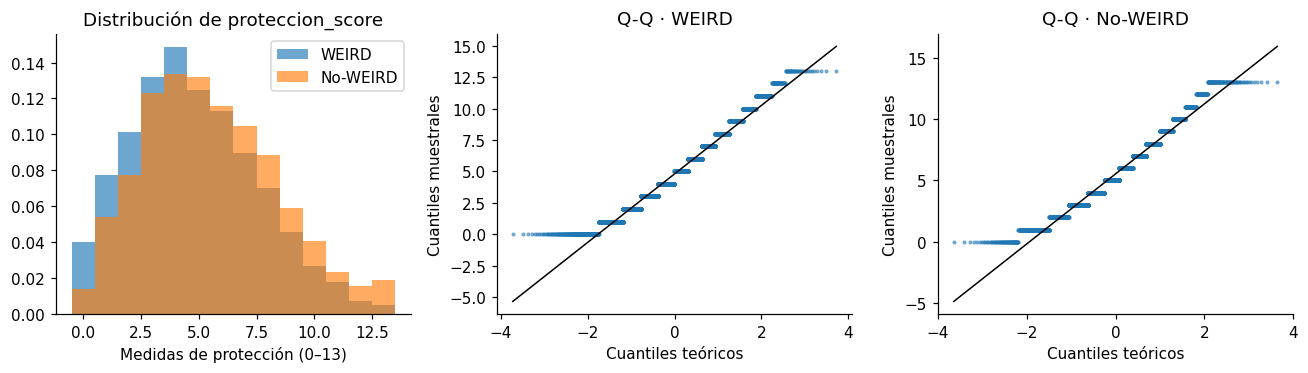

In [ ]:
h1 = df[["proteccion_score", "grupo_weird", "Country"]].dropna()
a = h1.loc[h1.grupo_weird == "WEIRD",    "proteccion_score"].values
b = h1.loc[h1.grupo_weird == "No-WEIRD", "proteccion_score"].values

print(pd.DataFrame({"n": [len(a), len(b)], "media": [a.mean(), b.mean()], "DE": [a.std(ddof=1), b.std(ddof=1)],
                    "mediana": [np.median(a), np.median(b)]}, index=["WEIRD", "No-WEIRD"]).round(3))

print("\nShapiro WEIRD    :", shapiro_big(a))
print("Shapiro No-WEIRD :", shapiro_big(b))
print("Levene           :", stats.levene(a, b))       # p ≈ 0.011 (varianzas levemente distintas)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
bins = np.arange(-0.5, 14.5, 1)
axs[0].hist(a, bins=bins, alpha=.65, density=True, label="WEIRD")
axs[0].hist(b, bins=bins, alpha=.65, density=True, label="No-WEIRD")
axs[0].legend(); axs[0].set_title("Distribución de proteccion_score"); axs[0].set_xlabel("Medidas de protección (0–13)")
qq(axs[1], a, "Q-Q · WEIRD"); qq(axs[2], b, "Q-Q · No-WEIRD")
plt.tight_layout(); plt.show()




**Decisión:** Shapiro rechaza normalidad (p < 0,001 en ambos grupos; la variable es un conteo entero de 0 a 13) → **Mann-Whitney U**. Se reportan además d de Cohen, diferencia de medias con IC 95%, correlación biserial por rangos con IC bootstrap y como sensibilidad el t-test de Welch porque Levene detecta una heterocedasticidad.

De acuerdo a los resultado obtenidos, como los datos no se distribuyen de forma "normal", se opta por elegir una prueba no paramétrica: Mann-Whitney para el análisis principal, pero sumó varios indicadores de soporte y una prueba secundaria: Welch para demostrar que las conclusiones son sólidas y confiables.

In [ ]:
n1, n2 = len(a), len(b)

mw = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic")
# z con corrección por empates (muchos empates: la variable toma solo 14 valores)
N_ = n1 + n2
_, tc = np.unique(np.concatenate([a, b]), return_counts=True)
var_u = n1 * n2 / 12 * ((N_ + 1) - (tc ** 3 - tc).sum() / (N_ * (N_ - 1)))
z = (mw.statistic - n1 * n2 / 2) / np.sqrt(var_u)

rbc  = 2 * mw.statistic / (n1 * n2) - 1                      # correlación biserial por rangos
cles = mw.statistic / (n1 * n2)                              # prob. de superioridad (WEIRD > No-WEIRD)
bs = [2 * stats.mannwhitneyu(rng.choice(a, n1), rng.choice(b, n2)).statistic / (n1 * n2) - 1 for _ in range(2000)]
rbc_ci = np.percentile(bs, [2.5, 97.5])

d, d_lo, d_hi = cohen_d(a, b)
tw = stats.ttest_ind(a, b, equal_var=False)
ci = tw.confidence_interval(0.95)

tabla_h1 = pd.DataFrame([
    ["Mann-Whitney U", f"U = {mw.statistic:,.1f}; z = {z:.2f}; p = {mw.pvalue:.2e}", "—"],
    ["Diferencia de medias (WEIRD − No-WEIRD)", f"{a.mean() - b.mean():.3f}", f"[{ci.low:.3f}; {ci.high:.3f}]"],
    ["d de Cohen", f"{d:.3f}", f"[{d_lo:.3f}; {d_hi:.3f}]"],
    ["Correlación biserial por rangos", f"{rbc:.3f}", f"[{rbc_ci[0]:.3f}; {rbc_ci[1]:.3f}]"],
    ["CLES", f"{cles:.3f}", "—"],
    ["Sensibilidad: Welch t", f"t = {tw.statistic:.2f}; gl = {tw.df:.0f}; p = {tw.pvalue:.2e}", "—"],
], columns=["Estadístico", "Valor", "IC 95%"])
display(tabla_h1)

# Sensibilidad: Es necesario excluir países fronterizos (Israel = 4, Polonia = 7)
sub = h1[~h1.Country.isin([4, 7])]
a2 = sub.loc[sub.grupo_weird == "WEIRD", "proteccion_score"].values
b2 = sub.loc[sub.grupo_weird == "No-WEIRD", "proteccion_score"].values
print("Sin Israel/Polonia -> d, IC:", [round(v, 3) for v in cohen_d(a2, b2)])

,Estadístico,Valor,IC 95%
0,Mann-Whitney U,"U = 15,914,317.5; z = -13.42; p = 4.80e-41",—
1,Diferencia de medias (WEIRD − No-WEIRD),-0.737,[-0.838; -0.635]
2,d de Cohen,-0.262,[-0.297; -0.226]
3,Correlación biserial por rangos,-0.141,[-0.160; -0.121]
4,CLES,0.430,—
5,Sensibilidad: Welch t,t = -14.21; gl = 10736; p = 1.97e-45,—


Sin Israel/Polonia -> d, IC: [np.float64(-0.253), np.float64(-0.291), np.float64(-0.214)]


Como se puede observar existe una exclusión intencional de Israel y Polonia, esta exclusión es sugerida teniendo en cuenta la categoría WEIRD, donde Israel tiene niveles socioeconómicos altos y una democracia propia de Occidente, pero geograficamente hace parte del Medio Oriente, con dinámicas culturales y sociopolíticas muy particulares, con respecto a Polonia, geográficamente pertenece a Europa Central y Oriental pero tiene una historia postcomunitaria reciente lo cual ahce que difiera de los países occidentales tradicionales.

Esta división se realiza con el fin de determinar la sesibilidad o robustez de los resultados mediante d de Cohen.
Los resultados generados se puede ver en los dos últimos valores del script anterior.

**Resultados obtenidos**

Existe una diferencia de 0,74 medidas (IC 95% [−0,84; −0,64])
d ≈ −0,26, lo cual se interpreta como un efecto pequeño según Cohen.
Existe una probabilidad de superioridad del 43 % frente al 50 % esperado bajo igualdad.

**Conclusión.**

Se rechaza la hipotesis nula H₀ (p ≈ 10⁻⁴¹), pero con N > 12.000 casi cualquier diferencia es significativa; lo relevante es la magnitud. Los participantes No-WEIRD usan en promedio 5,53 de 13 medidas frente a 4,79 de los WEIRD

Los resultados y la conclusión indican que es un patrón poblacional real pero débil para predecir a un individuo, y se mantiene al excluir a Israel y Polonia (d ≈ −0,25).

Los promedios por país muestran que lo impulsan sobre todo Sudáfrica (6,4) e India (6,2), y que EE. UU. tiene el menor uso (4,4). Como es autorreporte, la diferencia no equivale necesariamente a mejor protección real.

## Conocimiento técnico según nivel educativo (3 grupos)
Se crean las hipótesis **$H_0$:** y **$H_1$:**

**$H_0$:** *Conocimiento_score* tiene la misma distribución en Bajo, Medio y Alto.

**$H_1$:** Al menos un nivel se considera diferente.

          n  media    DE  mediana
Bajo   1534   2.92  0.85     2.86
Medio  5102   3.12  0.82     3.09
Alto   5588   3.36  0.83     3.36
Shapiro Bajo  : ShapiroResult(statistic=np.float64(0.9854198479857741), pvalue=np.float64(2.509199244698251e-11))
Shapiro Medio : ShapiroResult(statistic=np.float64(0.9947043337815757), pvalue=np.float64(1.3833398151872945e-12))
Shapiro Alto  : ShapiroResult(statistic=np.float64(0.9912254330655855), pvalue=np.float64(4.6239733798375273e-17))
Levene: LeveneResult(statistic=np.float64(1.9117608864869597), pvalue=np.float64(0.14786406789559922))


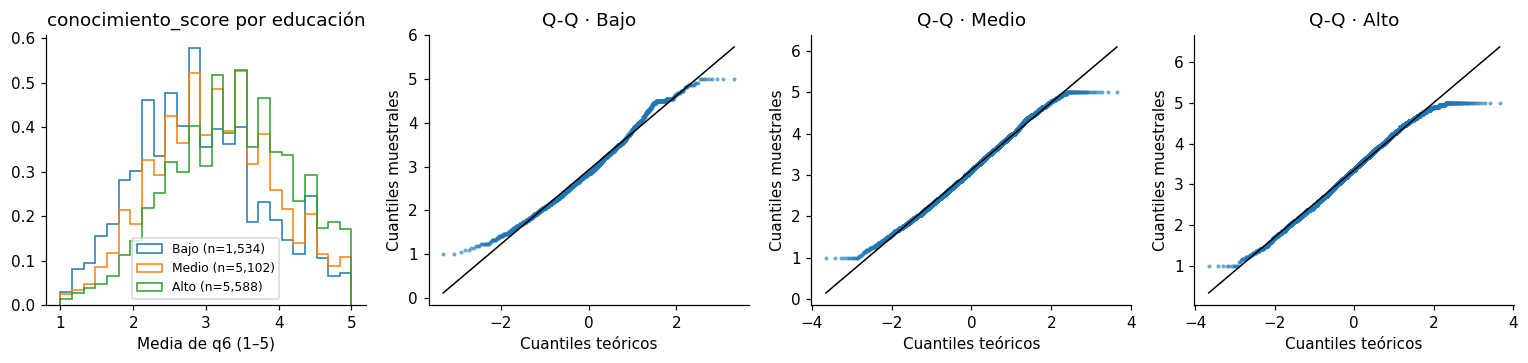

In [ ]:
h2 = df[["conocimiento_score", "edu_cat"]].dropna()
orden = ["Bajo", "Medio", "Alto"]
G = {g: h2.loc[h2.edu_cat == g, "conocimiento_score"].values for g in orden}

print(pd.DataFrame({"n": {g: len(v) for g, v in G.items()},
                    "media": {g: v.mean() for g, v in G.items()},
                    "DE": {g: v.std(ddof=1) for g, v in G.items()},
                    "mediana": {g: np.median(v) for g, v in G.items()}}).round(2))

for g in orden:
    print(f"Shapiro {g:6s}:", shapiro_big(G[g]))
print("Levene:", stats.levene(*G.values()))        # p ≈ 0.148 (varianzas homogéneas)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.4))
for g in orden:
    axs[0].hist(G[g], bins=25, density=True, histtype="step", lw=1.8, label=f"{g} (n={len(G[g]):,})")
axs[0].set_title("conocimiento_score por educación"); axs[0].set_xlabel("Media de q6 (1–5)"); axs[0].legend(fontsize=8)
for ax, g in zip(axs[1:], orden):
    qq(ax, G[g], f"Q-Q · {g}")
plt.tight_layout(); plt.show()

**Conclusión:** Al aplicar la prueba de normalidad de Shapiro-Wilk, se evidencia que no existe normalidad en los tres grupos (p < 0,001; con n > 1.500 por grupo el test detecta desviaciones mínimas), por lo tanto los datos no siguen una distribución normal perfecta.

Teniendo en cuenta que la prueba dio no normal, se optó por hacer uso de la prueba no paramétrica de Kruskal-Wallis, que se considera ideal para comparar 3 o más grupos cuando no hay normalidad. Este proceso se indica en el siguiente script:


In [ ]:
N, k = sum(len(v) for v in G.values()), 3

kw = stats.kruskal(*G.values())
eta2_H = (kw.statistic - k + 1) / (N - k)
bs = [(stats.kruskal(*[rng.choice(G[g], len(G[g])) for g in orden]).statistic - k + 1) / (N - k) for _ in range(1000)]
eta2_ci = np.percentile(bs, [2.5, 97.5])

fo = stats.f_oneway(*G.values())
allx = np.concatenate(list(G.values())); gm = allx.mean()
eta2_anova = sum(len(v) * (v.mean() - gm) ** 2 for v in G.values()) / ((allx - gm) ** 2).sum()

print(f"Kruskal-Wallis: H({k-1}) = {kw.statistic:.2f}; p = {kw.pvalue:.2e}; N = {N:,}")     # H ≈ 410.8; p ≈ 6e-90
print(f"eta2_H = {eta2_H:.4f}  IC95% [{eta2_ci[0]:.4f}; {eta2_ci[1]:.4f}]")                  # ≈ 0.0335 [0.028; 0.041]
print(f"ANOVA: F = {fo.statistic:.2f}; p = {fo.pvalue:.2e}; eta2 = {eta2_anova:.4f}")         # F ≈ 208.9; eta2 ≈ 0.033

Kruskal-Wallis: H(2) = 410.80; p = 6.26e-90; N = 12,224
eta2_H = 0.0335  IC95% [0.0276; 0.0405]
ANOVA: F = 208.85; p = 6.49e-90; eta2 = 0.0330


En el siguiente script se hace uso de post-hoc de Dunn con corrección de Holm.
Esto permite realizar un análisis de comparaciones múltiples por pares o *post-hoc* entre diferentes niveles como "Bajo", "Medio" o "Alto", combina pruebas estadísticas no paramétrica como es post-hoc de Dunn y paramétricas como Tukey HSD y calcula el tamaño del efecto mediante d de Cohen.

In [ ]:
allv = np.concatenate([G[g] for g in orden]); lab = np.concatenate([[g] * len(G[g]) for g in orden])
rk = stats.rankdata(allv); sigma2 = N * (N + 1) / 12 * stats.tiecorrect(rk)
R = {g: rk[lab == g].mean() for g in orden}
pares = [("Bajo", "Medio"), ("Bajo", "Alto"), ("Medio", "Alto")]

zs, ps = [], []
for g1, g2 in pares:
    zz = (R[g2] - R[g1]) / np.sqrt(sigma2 * (1 / len(G[g1]) + 1 / len(G[g2])))   # z > 0: g2 mayor que g1
    zs.append(zz); ps.append(2 * stats.norm.sf(abs(zz)))
ps = np.array(ps); o = np.argsort(ps); holm = np.empty(3); acum = 0
for i, idx in enumerate(o):
    acum = max(acum, min(1, (3 - i) * ps[idx])); holm[idx] = acum

tk = stats.tukey_hsd(*G.values()); tci = tk.confidence_interval(0.95)
idx = [(0, 1), (0, 2), (1, 2)]
filas = []
for (g1, g2), zz, ph, (i, j) in zip(pares, zs, holm, idx):
    dd = cohen_d(G[g2], G[g1])
    filas.append([f"{g2} − {g1}", round(zz, 2), f"{ph:.1e}", round(-tk.statistic[i, j], 3),
                  f"[{-tci.high[i, j]:.3f}; {-tci.low[i, j]:.3f}]", f"{dd[0]:.2f} [{dd[1]:.2f}; {dd[2]:.2f}]"])
display(pd.DataFrame(filas, columns=["Comparación", "z Dunn", "p Holm", "Dif. medias", "IC95% Tukey", "d de Cohen [IC95%]"]))
print (" ")
print ("Valores de Referencia teniendo en cuenta las funciones estadísticas (Dunn, Tukey HSD y d de Cohen):")
print ("Medio−Bajo: z=8.18, dif 0.199 [0.142; 0.255], d=0.24")
print ("Alto−Bajo: z=18.03, dif 0.433 [0.377; 0.489], d=0.52")
print ("Alto−Medio: z=14.54, dif 0.234 [0.197; 0.272], d=0.29")

,Comparación,z Dunn,p Holm,Dif. medias,IC95% Tukey,d de Cohen [IC95%]
0,Medio − Bajo,8.18,2.8e-16,0.199,[0.142; 0.255],0.24 [0.18; 0.30]
1,Alto − Bajo,18.03,3.1e-72,0.433,[0.377; 0.489],0.52 [0.46; 0.58]
2,Alto − Medio,14.54,1.3e-47,0.234,[0.197; 0.272],0.29 [0.25; 0.32]


 
Valores de Referencia teniendo en cuenta las funciones estadísticas (Dunn, Tukey HSD y d de Cohen):
Medio−Bajo: z=8.18, dif 0.199 [0.142; 0.255], d=0.24
Alto−Bajo: z=18.03, dif 0.433 [0.377; 0.489], d=0.52
Alto−Medio: z=14.54, dif 0.234 [0.197; 0.272], d=0.29


Como se observa al ejecutar el script, se tiene la estadística Z de Dunn, el valor *p* ajustado por Holm, la diferencia de medias, el intervalo de confianza de Tukey y el *d* de Cohen con su respectivo IC

**Análisis:** Se rechaza la hipótesis nula H₀: los tres niveles difieren entre sí y el conocimiento crece de forma monótona con la educación (medias 2,92 → 3,12 → 3,36 en una escala de 1 a 5).

η² ≈ 0,034 [0,028; 0,041] es un efecto mínimo, más cercano al umbral mínimo (0,01) que al mediano (0,06): la educación explica cerca del 3 % de la varianza.

La brecha entre Alto y Bajo (0,43 puntos) alcanza d ≈ 0,52, un efecto considerado como mediano, mientras que entre niveles contiguos la brecha se podría estimar como pequeña (d ≈ 0,24 y 0,29). Considerando con N > 12.000, el patrón no es solo un efecto del tamaño muestral, sin embargo la mayor parte de la variación del conocimiento ocurre dentro de cada nivel educativo; esto implica que la educación sirve como criterio orientativo, pero no es  suficiente, para segmentar capacitación en seguridad.

## 6. Regresión lineal múltiple (OLS con statsmodels)
**Pregunta:** Cómo se predice el *proteccion_score*, número de medidas usadas, a partir del conocimiento técnico: *conocimiento_score*, edad, nivel educativo y la experiencia en TI (pregunta 25)?

**Respuesta:** Es necesario un análisis con casos completos, teniendo en cuenta el dataset faltan *Age* en países como China, Arabia Saudita y Sudáfrica, además se excluye el ítem donde *Education* = 4.
Estos 2 campos se toman como numéricas ordinales, como en la fórmula del enunciado.

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

datos = df[["proteccion_score", "conocimiento_score", "Age", "Education", "q25", "Country"]].copy()
datos = datos[datos.Education.isin([1, 2, 3])].dropna().copy()
datos["q25"] = datos["q25"].astype(int)
print("n modelo:", len(datos), "| excluidos:", len(df) - len(datos))         # referencia: 8,959 | 3,391
print("Países en el modelo:", sorted(datos.Country.map(PAISES).unique()))   # No-WEIRD solo India y México

modelo_ols = smf.ols("proteccion_score ~ conocimiento_score + Age + Education + C(q25)",data=datos).fit()
print(modelo_ols.summary())
print ("Referencia: R2 = 0.2775; R2 aj = 0.2772; F = 860.0; AIC = 40949.5; BIC = 40985.0")
print ("Coef.: Intercept -0.394 | conocimiento 1.664 | Age 0.067 | Education 0.063 (p = 0.10) | C(q25)[T.2] -0.363")

n modelo: 8959 | excluidos: 3391
Países en el modelo: ['Alemania', 'EE. UU.', 'India', 'Israel', 'Italia', 'México', 'Polonia', 'Reino Unido', 'Suecia']
                            OLS Regression Results                            
Dep. Variable:       proteccion_score   R-squared:                       0.278
Model:                            OLS   Adj. R-squared:                  0.277
Method:                 Least Squares   F-statistic:                     860.0
Date:                Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:21:04   Log-Likelihood:                -20470.
No. Observations:                8959   AIC:                         4.095e+04
Df Residuals:                    8954   BIC:                         4.099e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      

In [ ]:
# Coeficientes con IC 95% y betas estandarizados
X = pd.DataFrame(modelo_ols.model.exog, columns=modelo_ols.model.exog_names)
beta_std = modelo_ols.params * X.std(ddof=1) / datos["proteccion_score"].std(ddof=1)
tabla_coef = pd.concat([modelo_ols.params.rename("coef"), modelo_ols.bse.rename("EE"),
                        modelo_ols.conf_int().rename(columns={0: "IC2.5%", 1: "IC97.5%"}),
                        beta_std.rename("beta_std"), modelo_ols.pvalues.rename("p")], axis=1).round(4)
tabla_coef.loc["Intercept", "beta_std"] = np.nan
tabla_coef
print ("Referencia beta_std: conocimiento 0.500 | Age 0.025 | Education 0.015 | q25=2 -0.062")

Referencia beta_std: conocimiento 0.500 | Age 0.025 | Education 0.015 | q25=2 -0.062


## 7. Diagnóstico de supuestos

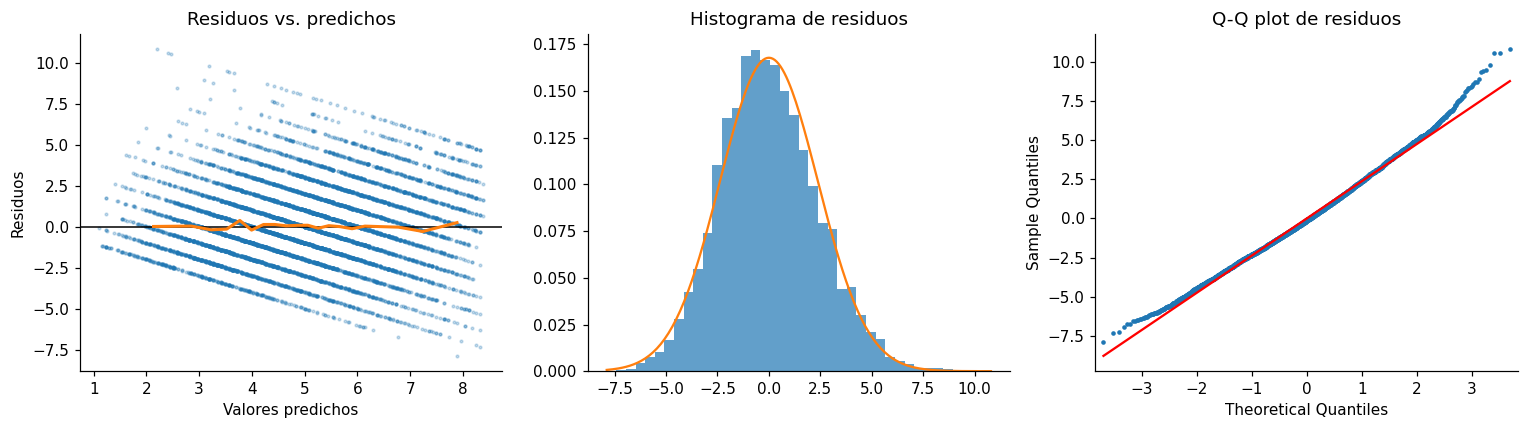

Shapiro-Wilk (5.000 al azar): ShapiroResult(statistic=np.float64(0.9967709722673189), pvalue=np.float64(6.313152007311861e-09))
Jarque-Bera                 : SignificanceResult(statistic=np.float64(128.56328432175954), pvalue=np.float64(1.2101453095717342e-28))
Kolmogorov-Smirnov          : KstestResult(statistic=np.float64(0.022531000512637456), pvalue=np.float64(0.00022070641139282092), statistic_location=np.float64(-0.09256171305663563), statistic_sign=np.int8(1))
Asimetría / curtosis exceso : 0.273 0.216


In [ ]:
resid, ajust = modelo_ols.resid, modelo_ols.fittedvalues

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
# Linealidad: residuos vs. predichos (con media por vigintil)
axs[0].scatter(ajust, resid, s=3, alpha=.25); axs[0].axhline(0, color="k", lw=1)
tr = pd.DataFrame({"f": ajust, "e": resid}).groupby(pd.qcut(ajust, 20, duplicates="drop"), observed=True).mean()
axs[0].plot(tr.f, tr.e, color="C1", lw=2); axs[0].set_title("Residuos vs. predichos")
axs[0].set_xlabel("Valores predichos"); axs[0].set_ylabel("Residuos")
# Normalidad: histograma + Q-Q
axs[1].hist(resid, bins=40, density=True, alpha=.7)
xs = np.linspace(resid.min(), resid.max(), 200); axs[1].plot(xs, stats.norm.pdf(xs, 0, resid.std(ddof=1)), color="C1")
axs[1].set_title("Histograma de residuos")
sm.qqplot(resid, line="s", ax=axs[2], markersize=2); axs[2].set_title("Q-Q plot de residuos")
plt.tight_layout(); plt.show()

print("Shapiro-Wilk (5.000 al azar):", shapiro_big(resid.values))      # W ≈ 0.995; p < 0.001
print("Jarque-Bera                 :", stats.jarque_bera(resid))        # 128.6; p ≈ 1e-28
print("Kolmogorov-Smirnov          :", stats.kstest((resid - resid.mean()) / resid.std(ddof=1), "norm"))   # D ≈ 0.0225
print("Asimetría / curtosis exceso :", round(stats.skew(resid), 3), round(stats.kurtosis(resid), 3))       # 0.273 / 0.216

**Linealidad:** la media de los residuos por vigintil de valores predichos se mantiene alrededor de 0, sin curvatura. Las bandas diagonales son esperables porque la variable dependiente es un conteo entero.

 **Normalidad:** los residuos tienen una leve cola derecha (asimetría ≈ 0,27); Shapiro, Jarque-Bera y KS rechazan por el tamaño de muestra, pero la desviación es pequeña y con n ≈ 9.000 la inferencia sobre los coeficientes es robusta.

In [ ]:
# Homocedasticidad: Breusch-Pagan
lm, lm_p, f, f_p = het_breuschpagan(resid, modelo_ols.model.exog)
print(f"Breusch-Pagan: LM = {lm:.2f} (p = {lm_p:.2e}); F = {f:.2f} (p = {f_p:.2e})")   # LM ≈ 216.7; F ≈ 55.5
# Multicolinealidad: VIF
Xv = modelo_ols.model.exog
vif = pd.Series([variance_inflation_factor(Xv, i) for i in range(1, Xv.shape[1])],
                index=modelo_ols.model.exog_names[1:], name="VIF").round(2)
print(vif)                                  # ≈ conocimiento 1.21 | Age 1.04 | Education 1.06 | q25 1.17 (todos < 5)

Breusch-Pagan: LM = 216.68 (p = 9.71e-46); F = 55.48 (p = 2.73e-46)
C(q25)[T.2]           1.17
conocimiento_score    1.21
Age                   1.04
Education             1.06
Name: VIF, dtype: float64


Breusch-Pagan rechaza homocedasticidad, así que se reajusta con errores estándar robustos **HC3**.

Referencia EE_HC3: Intercept 0.158 | conocimiento 0.0345 | Age 0.0249 | Education 0.0374 (p ≈ 0.095) | q25 0.0604
Cook máx = 0.0077 | > 1: 0 | > 4/n (0.00045): 440 (4.9%)
Apalancamiento máx: 0.0019


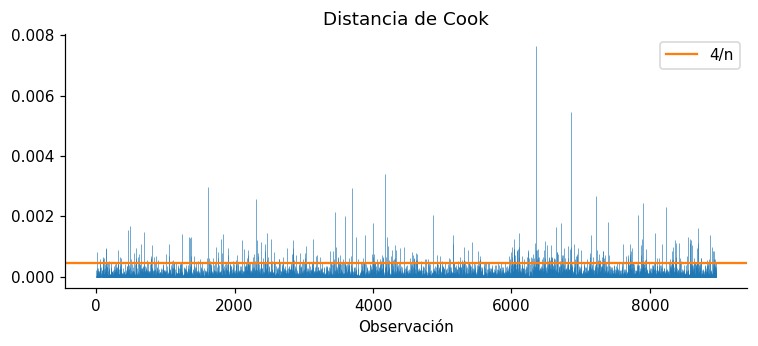

Referencia: Intercept -0.394 → -1.042 | conocimiento 1.664 → 1.829 | Age 0.067 → 0.088 | Education 0.063 → 0.022 | q25 -0.363 → -0.222


In [ ]:
modelo_hc3 = smf.ols("proteccion_score ~ conocimiento_score + Age + Education + C(q25)",
                     data=datos).fit(cov_type="HC3")
comp = pd.DataFrame({"coef": modelo_ols.params, "EE_OLS": modelo_ols.bse, "EE_HC3": modelo_hc3.bse,
                     "p_HC3": modelo_hc3.pvalues})
comp[["IC2.5%_HC3", "IC97.5%_HC3"]] = modelo_hc3.conf_int().values
comp.round(4)
print ("Referencia EE_HC3: Intercept 0.158 | conocimiento 0.0345 | Age 0.0249 | Education 0.0374 (p ≈ 0.095) | q25 0.0604")

# Observaciones influyentes: distancia de Cook
infl = modelo_ols.get_influence()
cook = infl.cooks_distance[0]; n = len(datos); umbral = 4 / n

print(f"Cook máx = {cook.max():.4f} | > 1: {(cook > 1).sum()} | > 4/n ({umbral:.5f}): {(cook > umbral).sum()} ({(cook > umbral).mean():.1%})")
print("Apalancamiento máx:", round(infl.hat_matrix_diag.max(), 4))     # Cook máx ≈ 0.0077; > 4/n: 440 (4.9%); hat máx ≈ 0.0019

fig, ax = plt.subplots(figsize=(8, 3))
ax.vlines(np.arange(n), 0, cook, lw=.4); ax.axhline(umbral, color="C1", ls="-", label="4/n")
ax.set_title("Distancia de Cook"); ax.set_xlabel("Observación"); ax.legend(); plt.show()

# Estabilidad de los coeficientes sin las observaciones con D > 4/n
m_trim = smf.ols("proteccion_score ~ conocimiento_score + Age + Education + C(q25)", data=datos[cook <= umbral]).fit()
pd.DataFrame({"completo": modelo_ols.params, "sin D>4/n": m_trim.params}).round(3)
print ("Referencia: Intercept -0.394 → -1.042 | conocimiento 1.664 → 1.829 | Age 0.067 → 0.088 | Education 0.063 → 0.022 | q25 -0.363 → -0.222")

**Interpretación del diagnóstico:**

Ninguna observación se acerca a D = 1 (máximo ≈ 0,008) y el apalancamiento máximo es ≈ 0,002, por lo tanto no hay puntos que distorsionen el modelo; el 4,9 % que supera 4/n es el esperable con un umbral tan estricto. Al reajustar sin ellos, los signos no cambian y el conocimiento sigue dominando, sin embargo se aprecia que el coeficiente del ítem *q25* se reduce de −0,36 a −0,22, así que su magnitud es la menos estable.

Se conservan todos los casos: son respuestas válidas dentro de una escala acotada, es decir que no existen errores de captura.

Con HC3 los errores estándar casi no cambian y las conclusiones se mantienen. VIF < 1,3 descarta multicolinealidad.

**Interpretación de los coeficientes:**
- **Conocimiento:** +1,66 medidas por cada punto de la escala 1-5 (IC 95% [1,60; 1,73]; β = 0,50). Es el predictor dominante.
- **q25** (sin experiencia en TI frente a con experiencia): -0,36 medidas (IC [−0,48; −0,25]; β = -0,06).
- **Edad:** +0,07 medidas por categoría (p = 0,008; β = 0,02), un efecto muy pequeño.
- **Educación:** +0,06 medidas por nivel, **no significativo** (p = 0,10; HC3 p = 0,095). La educación sí se asociaba con el conocimiento (H2); al controlar por conocimiento deja de aportar, lo que es compatible con que su efecto pase por el conocimiento.

El modelo explica el 27,8 % de la varianza (R² ajustado 0,277), consierando que son asociaciones y no causalidad puesto que tanto el conocimiento como la conducta provienen de la misma encuesta.

## 8. Conclusiones
- **H1:** Los países clasificados como No-WEIRD utilizan más medidas de protección que los países WEIRD (5,53 vs. 4,79 de 13); la diferencia se considera significativa pero pequeña (d ≈ -0,26).
- **H2:** El conocimiento aumenta con la educación, con un efecto pequeño en conjunto (η² ≈ 0,034) y efecto mediano entre Alto y Bajo (d ≈ 0,52).
- **Regresión:** R² ≈ 0,28. El conocimiento técnico es el factor dominante (β ≈ 0,50); la experiencia en TI aporta, pero no se considera significativo (-0,36 medidas si no se tiene experiencia en TI), la edad no se considera relevante y la educación no es significativa una vez controlado el conocimiento.
- **Diagnóstico:** Linealidad, normalidad aproximada y VIF < 5 se cumplen; no hay puntos influyentes (Cook máx. ≈ 0,008). Hay heterocedasticidad (Breusch-Pagan), corregida con HC3 sin cambiar las conclusiones.

**Limitaciones**
- Indices y control de calidad siguen el diccionario, con dos ajustes documentados en las preguntas *q20r1* ("ninguna medida") no se suma, y en la pregunta de control donde se evalúa por país porque en Polonia el valor esperado es distinto.
- La regresión no incluye China, Arabia Saudita ni Sudáfrica debido a la carencia de datos en el campo de edad (*Age*) y entre los claificados como No-WEIRD solo participan India y México.
- *proteccion_score* es un conteo (0 - 13) tratado como continuo, y los campos *Age*/*Education* son datos ordinales tratados como numéricos, teniendo en cuenta la solicitud del enunciado.
- El diseño es transversal y de autorreporte, lo que implica que no permite inferir causalidad.